# 29. The Hadamard Product
Run the cells in order. Keep `lafp.py` in the same folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lafp import *
%matplotlib inline

Kernels built by Hadamard products. For $40$ random points on a line, the Gram matrices of a linear kernel $1+xy$ (left), of the cosine kernel $\cos(3(x-y))$ (middle) and of their Hadamard product (right), all positive semidefinite. Bottom: their eigenvalues on a log scale. The linear kernel has rank $2$ and the cosine kernel rank $2$, so the product has rank at most $4$; the product of a rank-$r$ and a rank-$s$ positive semidefinite matrix has rank at most $rs$.

findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


findfont: Failed to find font weight semibold for DejaVu Serif, now using 700.


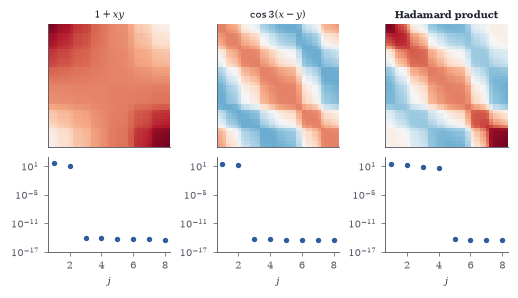

In [2]:
rng = np.random.default_rng(1); xs = np.sort(rng.uniform(-1, 1, 40))
K1 = 1 + np.outer(xs, xs); K2 = np.cos(3 * (xs[:, None] - xs[None, :])); K3 = K1 * K2
fig, axs = plt.subplots(2, 3, figsize=(W, 2.6), gridspec_kw={"height_ratios": [1.3, 1]})
for c, (Km, ttl) in enumerate([(K1, "$1+xy$"), (K2, r"$\cos 3(x-y)$"), (K3, "Hadamard product")]):
    axs[0, c].imshow(Km, cmap=CMAP, vmin=-2, vmax=2); axs[0, c].set_xticks([]); axs[0, c].set_yticks([]); axs[0, c].set_title(ttl, fontsize=6.5)
    ev = np.sort(np.linalg.eigvalsh(Km))[::-1]; axs[1, c].semilogy(np.arange(1, 9), np.maximum(ev[:8], 1e-17), "o", color=BLUE, ms=2.5); axs[1, c].set_ylim(1e-17, 1e3); axs[1, c].set_xlabel("$j$", fontsize=6)

Schur's lower bound in action: for $300$ random pairs of $6\times6$ positive definite matrices, $\lambda_{\min}(A\circ B)$ (vertical) against Schur's bound $\lambda_{\min}(A)\min_i b_{ii}$ (horizontal, blue) and the weaker Kronecker bound $\lambda_{\min}(A)\lambda_{\min}(B)$ (grey). All points lie above the diagonal; Schur's bound is much closer.

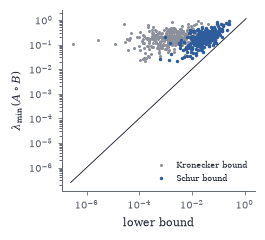

In [3]:
rng = np.random.default_rng(2); pts = []
for _ in range(300):
    Xa = rng.normal(size=(6, 9)); Xb = rng.normal(size=(6, 7)) * rng.uniform(0.3, 1.5, 7); Am, Bm = Xa @ Xa.T / 9, Xb @ Xb.T / 7
    la, lb, lab = np.linalg.eigvalsh(Am)[0], np.linalg.eigvalsh(Bm)[0], np.linalg.eigvalsh(Am * Bm)[0]; pts.append((la * Bm.diagonal().min(), la * lb, lab))
pts = np.array(pts)
fig, ax = plt.subplots(figsize=(W * 0.5, W * 0.45))
ax.loglog(pts[:, 1], pts[:, 2], ".", color=GRAY, ms=2, label="Kronecker bound"); ax.loglog(pts[:, 0], pts[:, 2], ".", color=BLUE, ms=2.5, label="Schur bound")
lim = [pts[:, :2].min() * 0.8, pts[:, 2].max() * 1.2]; ax.plot(lim, lim, color=INK, lw=0.6); ax.set_xlabel("lower bound"); ax.set_ylabel(r"$\lambda_{\min}(A\circ B)$"); ax.legend(fontsize=5.5)

Triangular truncation is unbounded. For the Toeplitz matrix $X_{ij}=1/(i-j+\frac12)$, the operator norm of $X$ stays below $\pi$ (grey), while the norm of its lower triangular part grows like $\frac{1}{\pi}\log n$ times $\lVert X\rVert$ (blue, with a fitted line of slope $\frac1\pi$ in $\log n$). The ratio is a lower bound for the norm of the causal-mask multiplier.

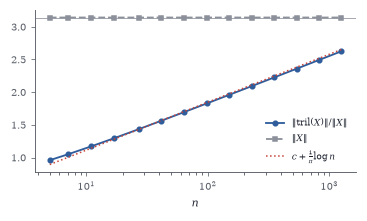

In [4]:
ns = np.unique(np.logspace(0.7, 3.1, 14).astype(int)); rat = []; nx = []
for n in ns:
    i = np.arange(n); Xh = 1.0 / (i[:, None] - i[None, :] + 0.5); a = np.linalg.norm(Xh, 2); b = np.linalg.norm(np.tril(Xh), 2); rat.append(b / a); nx.append(a)
fig, ax = plt.subplots(figsize=(W * 0.7, 1.9))
ax.semilogx(ns, rat, "o-", color=BLUE, ms=3, label=r"$\|\mathrm{tril}(X)\|/\|X\|$"); ax.semilogx(ns, nx, "s--", color=GRAY, ms=2.5, label=r"$\|X\|$")
cfit = np.mean(np.array(rat) - np.log(ns) / np.pi); ax.semilogx(ns, cfit + np.log(ns) / np.pi, ":", color=RED, lw=1, label=r"$c+\frac{1}{\pi}\log n$")
ax.axhline(np.pi, color=GRAY, lw=0.5); ax.set_xlabel("$n$"); ax.legend(fontsize=6)

Fractional Hadamard powers of $A=(1+\varepsilon x_ix_j)$ with $n=6$ distinct points $x_i$ and $\varepsilon=0.6$. The smallest eigenvalue of $A^{\circ r}$ (blue, on a signed logarithmic scale) is nonnegative (zero up to rounding, red dots) at the integers $r=0,1,2,3$ and positive for $r\ge n-2=4$, but negative on the open intervals in between, exactly as the FitzGerald–Horn theorem predicts.

Text(0, 0.5, 'sign$\\cdot\\log_{10}(1+|\\lambda_{\\min}|/10^{-15})$')

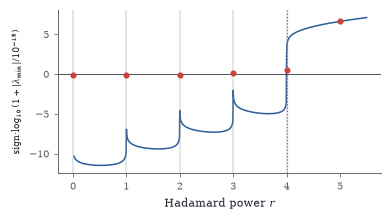

In [5]:
xx6 = np.linspace(0.3, 1.0, 6); A6 = 1 + 0.6 * np.outer(xx6, xx6); rs = np.linspace(0.02, 5.5, 900)
lm = np.array([np.linalg.eigvalsh(A6 ** r)[0] for r in rs])
fig, ax = plt.subplots(figsize=(W * 0.75, 1.9))
ax.plot(rs, np.sign(lm) * np.log10(1 + np.abs(lm) / 1e-15), color=BLUE, lw=1)
ax.axhline(0, color=INK, lw=0.5); ax.axvline(4, color=RED, ls=":", lw=0.8)
for k in range(5): ax.axvline(k, color=GRAY, lw=0.3)
li = np.array([np.linalg.eigvalsh(A6 ** k)[0] for k in range(6)]); ax.plot(range(6), np.sign(li) * np.log10(1 + np.abs(li) / 1e-15), "o", color=RED, ms=3, zorder=4)
ax.set_xlabel("Hadamard power $r$"); ax.set_ylabel(r"sign$\cdot\log_{10}(1+|\lambda_{\min}|/10^{-15})$", fontsize=6)

In [6]:
rng = np.random.default_rng(3)
for _ in range(4):
    Xa, Xb = rng.normal(size=(5, 7)), rng.normal(size=(5, 7)); Ap, Bp = Xa @ Xa.T, Xb @ Xb.T
    lhs, mid, rhs = np.linalg.det(Ap * Bp), np.linalg.det(Ap) * np.prod(np.diag(Bp)), np.linalg.det(Ap @ Bp)
    print(f"det(AoB) = {lhs:10.2f} >= detA*prod(b_ii) = {mid:10.2f} >= det(AB) = {rhs:10.2f}   ratio {lhs/mid:.2f}")

det(AoB) = 239533253.14 >= detA*prod(b_ii) = 11776924.93 >= det(AB) = 1647846.89   ratio 20.34
det(AoB) = 165855183.03 >= detA*prod(b_ii) = 29736978.30 >= det(AB) = 4638302.90   ratio 5.58
det(AoB) = 16160740.77 >= detA*prod(b_ii) = 3159801.93 >= det(AB) =   89613.79   ratio 5.11
det(AoB) = 10490260.43 >= detA*prod(b_ii) = 1358454.12 >= det(AB) =  262370.24   ratio 7.72


In [7]:
rng = np.random.default_rng(4); G = rng.normal(size=(6, 3)); Mc = G @ G.T; d = np.sqrt(np.diag(Mc)); Mc = Mc / np.outer(d, d)
ratios = [np.linalg.norm(Mc * X, 2) / np.linalg.norm(X, 2) for X in rng.normal(size=(2000, 6, 6))]
print("max ||M o X|| / ||X|| over 2000 random X:", round(max(ratios), 4), "  (bound: max m_ii = 1)")

max ||M o X|| / ||X|| over 2000 random X: 0.9488   (bound: max m_ii = 1)
